# Running PyTorch model with learning curves

This notebook demonstrates using a PyTorch CNN with typical training loop and validation curves (no sklearn pipeline).

### Step 1: Import libraries

In [ ]:
from tqdm import tqdm
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, cohen_kappa_score
from collections import defaultdict
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from fnirsatlas.dl.DLModelBase import DLModelBase
from fnirsatlas.feature_extraction import ChannelSplitter, StandardScalerND
from fnirsatlas.io import fNIRSAtlasDataset

seed = 42
np.random.seed(seed)
torch.manual_seed(seed)

### Step 2: Define CNN model

Create a CNN extending **DLModelBase** with sklearn-like interface:
- 1D convolutions for temporal then spatial filtering  
- ReLU activations and dropout for regularization
- Linear layer for final classification

In [2]:
class SimpleNet(DLModelBase):
    def __init__(self, T, n_chs, num_classes, p_dropout=0.5, **kwargs):
        super().__init__(**kwargs)
        self.T = T
        self.n_chs = n_chs
        self.num_classes = num_classes
        self.p_dropout = p_dropout
        self.layers = nn.Sequential(
            nn.Conv2d(2, 4, kernel_size=(1, T)),
            nn.ReLU(),
            nn.Dropout(self.p_dropout),
            nn.Conv2d(4, 8, kernel_size=(n_chs, 1)),
            nn.ReLU(),
            nn.Dropout(self.p_dropout),
            nn.Flatten(),
            nn.Linear(8, num_classes),
        )

    def forward(self, x):
        return self.layers(x)


### Step 3: Load and preprocess data

Manually load processed data and apply preprocessing:
1. **ChannelSplitter**: Reshape data for CNN input format
2. Apply classification task mapping

In [3]:
# Load data
dataset_name = "bnci"
# set_task() keeps the conditions of the first classification task and maps them to class labels
X, y, groups, info = fNIRSAtlasDataset(dataset_name).set_task().as_tuple()

# Split channels (n, c, t) -> (n, ch_type, c/2, t)
X = ChannelSplitter(info["ch_names"]).fit_transform(X)

# Parameters for the model
_, _, n_chs, T = X.shape
num_classes = np.unique(y).shape[0]


### Step 4: Run cross-validation with learning curves

Execute 5-fold cross-validation with validation on each epoch:
- Track validation accuracy and predictions per epoch
- Use typical PyTorch training loop (not sklearn pipeline)
- Standardize training and validation data with statistics from the training data

In [4]:
# Cross-validation
seeds = [42, 43, 44, 45, 46]
split_metrics = defaultdict(list)
for seed in seeds:
    cv = GroupKFold(n_splits=5, shuffle=True, random_state=seed)
    for train_ix, test_ix in tqdm(
        list(cv.split(X, y, groups)),
        desc=f"{dataset_name} 5-fold CV (seed {seed})",
    ):
        X_train, y_train = X[train_ix], y[train_ix]
        X_test, y_test = X[test_ix], y[test_ix]
        scaler = StandardScalerND(dim=(0, 2, 3))
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)
        model = SimpleNet(T, n_chs, num_classes)
        model.fit(X_train, y_train, X_val=X_test, y_val=y_test)
        for k, v in model.val_metrics.items():
            split_metrics[k].append(v)
        split_metrics["test_ix"].append(test_ix)

# Compute metrics
y_true = np.concatenate([y_true[-1] for y_true in split_metrics["y_true"]])
y_pred = np.concatenate([y_pred[-1] for y_pred in split_metrics["y_pred"]])
acc = accuracy_score(y_true, y_pred.argmax(axis=-1))
kappa_score = cohen_kappa_score(y_true, y_pred.argmax(axis=-1))
print(f"5-fold CV acc: {acc:.3f}, kappa: {kappa_score:.3f}")


bnci 5-fold CV (seed 46): 100%|██████████| 5/5 [00:02<00:00,  2.40it/s]

5-fold CV acc: 0.856, kappa: 0.713


### Step 5: Plot learning curves

Visualize validation accuracy across epochs and folds to analyze model convergence.

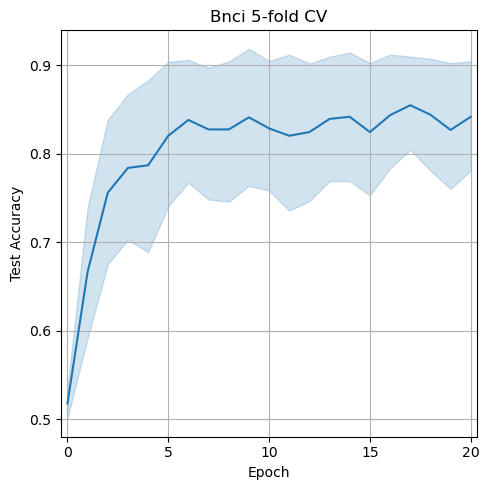

In [5]:
# Plot test accuracy curve
rows = []
n_splits = len(split_metrics["val_acc"])
n_epochs = len(split_metrics["val_acc"][0])
for split_ix in range(n_splits):
    for epoch_ix in range(n_epochs):
        rows.append(
            {
                "split_ix": split_ix,
                "epoch_ix": epoch_ix,
                "val_acc": split_metrics["val_acc"][split_ix][epoch_ix],
            }
        )
df = pd.DataFrame(rows)

plt.figure(figsize=(5, 5))
sns.lineplot(data=df, x="epoch_ix", y="val_acc")
plt.title(f"{dataset_name.capitalize()} 5-fold CV")
plt.xlabel("Epoch")
plt.ylabel("Test Accuracy")
plt.xticks(np.arange(0, 21, 5))
plt.xlim(0 - 0.3, 20 + 0.3)
plt.grid(True)
plt.tight_layout()
fig_path = Path("figures") / f"{dataset_name}_curve.png"
fig_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
